# **1. (5 pts) Build Deep Neural Network – LeNet5**

### 1.1 Import Libraries and Set Random Seed

In [1]:
import csv
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0)

### 1.2 Load MNIST Dataset (mnist_train.csv, mnist_test.csv)

In [2]:
class MNISTCSV(Dataset):
    def __init__(self, path):
        self.x = []
        self.y = []
        with open(path, "r", newline="") as f:
            reader = csv.reader(f)
            for row in reader:
                try:
                    label = int(float(row[0]))
                except:
                    continue
                pixels = [float(v) for v in row[1:]]
                self.y.append(label)
                self.x.append(pixels)

        self.x = torch.tensor(self.x, dtype=torch.float32) / 255.0
        self.y = torch.tensor(self.y, dtype=torch.long)

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self, idx):
        img = self.x[idx].view(1, 28, 28)
        img = F.pad(img, (2, 2, 2, 2), mode="constant", value=0.0)
        return img, self.y[idx]

### 1.3 Create Data Loaders

In [3]:
train_dataset = MNISTCSV("mnist_train.csv")
test_dataset  = MNISTCSV("mnist_test.csv")

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False)

len(train_dataset), len(test_dataset)

(60000, 10000)

### 1.4 Define LeNet-5 Architecture

In [4]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=0)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=0)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = self.pool1(x)
        x = torch.tanh(self.conv2(x))
        x = self.pool2(x)
        x = x.view(x.size(0), -1)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)
        return x

# **2. (5 pts) Training**

### 2.1 Define Loss Function and Optimizer (SGD)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)

device

device(type='cpu')

### 2.2 Training and Evaluation Functions

In [6]:
def accuracy_from_logits(logits, y):
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_acc = 0.0
    total_samples = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        batch_size = y.size(0)
        total_acc += accuracy_from_logits(logits, y) * batch_size
        total_samples += batch_size

    return total_acc / total_samples

def evaluate(model, loader, device):
    model.eval()
    total_acc = 0.0
    total_samples = 0

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            logits = model(x)
            batch_size = y.size(0)
            total_acc += accuracy_from_logits(logits, y) * batch_size
            total_samples += batch_size

    return total_acc / total_samples

### Train the Network (At Least 10 Epochs)

In [7]:
epochs = 10

for epoch in range(1, epochs + 1):
    train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_acc = evaluate(model, test_loader, device)

    print(f"Epoch {epoch:02d} | Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f}")

Epoch 01 | Train Acc: 0.8783 | Test Acc: 0.9720
Epoch 02 | Train Acc: 0.9758 | Test Acc: 0.9776
Epoch 03 | Train Acc: 0.9827 | Test Acc: 0.9841
Epoch 04 | Train Acc: 0.9875 | Test Acc: 0.9864
Epoch 05 | Train Acc: 0.9889 | Test Acc: 0.9847
Epoch 06 | Train Acc: 0.9914 | Test Acc: 0.9888
Epoch 07 | Train Acc: 0.9927 | Test Acc: 0.9879
Epoch 08 | Train Acc: 0.9942 | Test Acc: 0.9850
Epoch 09 | Train Acc: 0.9952 | Test Acc: 0.9891
Epoch 10 | Train Acc: 0.9969 | Test Acc: 0.9884


In [8]:
final_train_acc = evaluate(model, train_loader, device)
final_test_acc = evaluate(model, test_loader, device)

print("Final Training Accuracy:", round(final_train_acc, 4))
print("Final Testing Accuracy :", round(final_test_acc, 4))

Final Training Accuracy: 0.9979
Final Testing Accuracy : 0.9884


In [9]:
# Cell A — quick file-load counts (run in same env)
print(len(train_dataset), len(test_dataset))   # expect 60000, 10000

60000 10000


In [10]:
# Cell B — check for any identical images across train/test (slow but robust)
# Converts flattened tensors into bytes hash for quick set membership
import hashlib

def hash_tensor(t):
    return hashlib.sha1(t.numpy().tobytes()).hexdigest()

train_hashes = set()
for i in range(len(train_dataset)):
    img, _ = train_dataset[i]
    train_hashes.add(hash_tensor(img.view(-1)))

overlap = 0
for j in range(len(test_dataset)):
    img, _ = test_dataset[j]
    if hash_tensor(img.view(-1)) in train_hashes:
        overlap += 1

print("overlap count (should be 0):", overlap)

overlap count (should be 0): 0


In [11]:
# Cell C — final strict evaluation
model.eval()
correct = 0
total = 0
import torch
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        preds = torch.argmax(logits, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

print("Strict Test Accuracy:", correct / total)

Strict Test Accuracy: 0.9884


In [12]:
# Cell D — confusion matrix
import numpy as np
num_classes = 10
conf = np.zeros((num_classes, num_classes), dtype=int)

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)
        preds = torch.argmax(model(x), dim=1)
        for t, p in zip(y.cpu().numpy(), preds.cpu().numpy()):
            conf[t, p] += 1

print("Confusion matrix:\n", conf)
per_class = conf.diagonal() / conf.sum(axis=1)
for i, a in enumerate(per_class):
    print(f"class {i} acc: {a:.4f}")
print("Overall:", conf.diagonal().sum() / conf.sum())

Confusion matrix:
 [[ 973    0    1    0    0    0    2    1    2    1]
 [   0 1129    2    1    0    0    2    0    1    0]
 [   1    0 1027    1    1    0    0    1    0    1]
 [   0    0    1 1002    0    4    0    1    2    0]
 [   0    0    2    0  974    0    2    1    0    3]
 [   2    0    0    5    0  881    3    0    1    0]
 [   2    2    6    0    3    0  942    0    3    0]
 [   0    2    6    1    0    0    0 1016    1    2]
 [   3    0   10    3    0    0    0    1  954    3]
 [   0    1    1    2    9    2    1    7    0  986]]
class 0 acc: 0.9929
class 1 acc: 0.9947
class 2 acc: 0.9952
class 3 acc: 0.9921
class 4 acc: 0.9919
class 5 acc: 0.9877
class 6 acc: 0.9833
class 7 acc: 0.9883
class 8 acc: 0.9795
class 9 acc: 0.9772
Overall: 0.9884


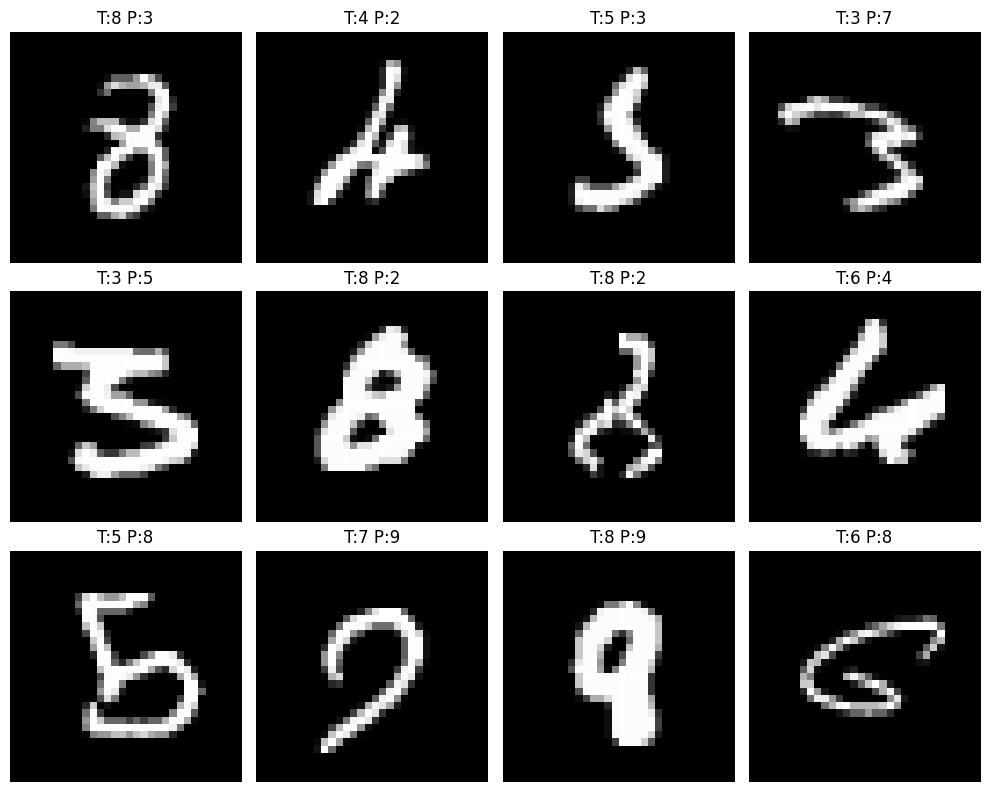

In [13]:
# Cell E — display some mistakes
import matplotlib.pyplot as plt

mis_xs = []
mis_ys = []
mis_ps = []
model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)
        preds = torch.argmax(model(x), dim=1)
        for img, t, p in zip(x.cpu(), y.cpu(), preds.cpu()):
            if t != p:
                mis_xs.append(img)
                mis_ys.append(int(t))
                mis_ps.append(int(p))
            if len(mis_xs) >= 12:
                break
        if len(mis_xs) >= 12:
            break

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
axes = axes.flatten()
for i in range(len(mis_xs)):
    axes[i].imshow(mis_xs[i].view(32,32), cmap='gray')
    axes[i].set_title(f"T:{mis_ys[i]} P:{mis_ps[i]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()